# Module 20 — Protéines et structure : du repliement Ig aux modèles qui voient en 3D

> **Objectif** : relier la séquence, la numérotation IMGT et la **structure 3D** des domaines de la superfamille des immunoglobulines, puis apprendre à utiliser la structure dans un modèle : cartes de contacts, graphes de résidus et **réseaux de neurones sur graphes** (GNN), délimitation de domaines à partir de la structure, alphabets structuraux (3Di de Foldseek) et PLM « conscients de la structure » (SaProt, ESM3), prédicteurs de structure (ESMFold, AlphaFold, ImmuneBuilder).

| | |
|---|---|
| **Durée estimée** | 3 h |
| **Prérequis** | Module 9 (PLM) ; fil rouge 1–3 ; module 19 (contacts depuis l'attention) |
| **Librairies** | `numpy`, `scipy`, `scikit-learn`, `matplotlib` ; `gemmi` ou `biopython`, `torch`, `torch_geometric`, `transformers`, Foldseek (section 7) |

> ⚙️ **Données 3D.** Je n'ai pas accès à la PDB depuis cet environnement. Les démonstrations utilisent une **maquette idéalisée** du repliement Ig, construite à partir de la numérotation IMGT (brins β, feuillets, boucles des CDR en haut du domaine) : elle respecte la **topologie** (qui est voisin de qui), pas la géométrie fine. La section 7 donne le code pour de vraies structures (PDB, IMGT/3Dstructure-DB, prédictions ESMFold ou ImmuneBuilder).

**Plan**

1. Le repliement Ig vu par la numérotation IMGT
2. Une maquette 3D d'un domaine V
3. Cartes de contacts : ce que la séquence ne montre pas
4. GNN : faire passer des messages entre voisins dans l'espace
5. Délimiter des domaines à partir de la structure
6. Alphabets structuraux : la structure comme une séquence
7. Sur de vraies structures : PDB, ESMFold, ImmuneBuilder, Foldseek, SaProt, ESM3
8. Ce que cela change pour ProtAnnotML
9. Récapitulatif et exercices

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
ROOT = Path.cwd().parent / "projet_protannotml"
sys.path.insert(0, str(ROOT))
from protannotml.synth import load_jsonl
from protannotml.imgt import parse_pos, region_of

examples = load_jsonl(Path("data_protannotml") / "examples.jsonl")
rng = np.random.default_rng(0)

## 1. Le repliement Ig vu par la numérotation IMGT

Un domaine V est un **sandwich β** : deux feuillets de brins antiparallèles qui se font face, reliés par un pont disulfure entre la 1st-CYS 23 (brin B) et la 2nd-CYS 104 (brin F). La numérotation IMGT a été construite pour que **chaque position corresponde à une place fixe dans ce repliement**, quelle que soit l'espèce ou le récepteur : c'est ce qui permet de comparer des structures, et c'est pourquoi les « Colliers de Perles » d'IMGT représentent la séquence directement sur la topologie.

| Brin ou boucle | Positions IMGT | Feuillet | Rôle |
|---|---|---|---|
| A | 1–15 | A B E D | N-terminal |
| B | 16–26 | A B E D | porte la 1st-CYS 23 |
| BC (CDR1-IMGT) | 27–38 | boucle | site de liaison |
| C | 39–46 | G F C C' C" | porte la CONSERVED-TRP 41 |
| C' | 47–55 | G F C C' C" | interface VH/VL |
| C'C" (CDR2-IMGT) | 56–65 | boucle | site de liaison |
| C" | 66–74 | G F C C' C" | |
| D | 75–84 | A B E D | |
| E | 85–96 | A B E D | porte l'hydrophobe 89 |
| F | 97–104 | G F C C' C" | porte la 2nd-CYS 104 |
| FG (CDR3-IMGT) | 105–117 | boucle | site de liaison |
| G | 118–128 | G F C C' C" | J-TRP/PHE 118 |

Deux conséquences immédiates :
- les trois CDR, éloignés dans la **séquence** (positions 27, 56, 105), sont **voisins dans l'espace** : ils forment ensemble, au sommet du domaine, le site de liaison à l'antigène ;
- les caractéristiques trouvées par le SAE du module 19 autour des positions 47–52 tombent dans le **brin C'**, celui de l'interface entre domaines VH et VL : une piste concrète pour l'hypothèse laissée ouverte alors.

## 2. Une maquette 3D d'un domaine V

On place chaque position IMGT dans l'espace : chaque brin est un segment de droite dans son feuillet (feuillets séparés de 10 Å, brins espacés de 4,8 Å, résidus espacés de 3,3 Å le long d'un brin), avec le sens de parcours qui alterne de façon cohérente (B monte vers le haut, C redescend, etc.), et les boucles sont des arcs qui relient les extrémités des brins, en haut pour les CDR. Les positions absentes d'une séquence (gaps IMGT) ne sont simplement pas placées : la géométrie reste la même pour toutes les séquences, comme la numérotation.

sequence separation C23-C104: 74 residues; spatial distance in the mock-up: 10.7 Å


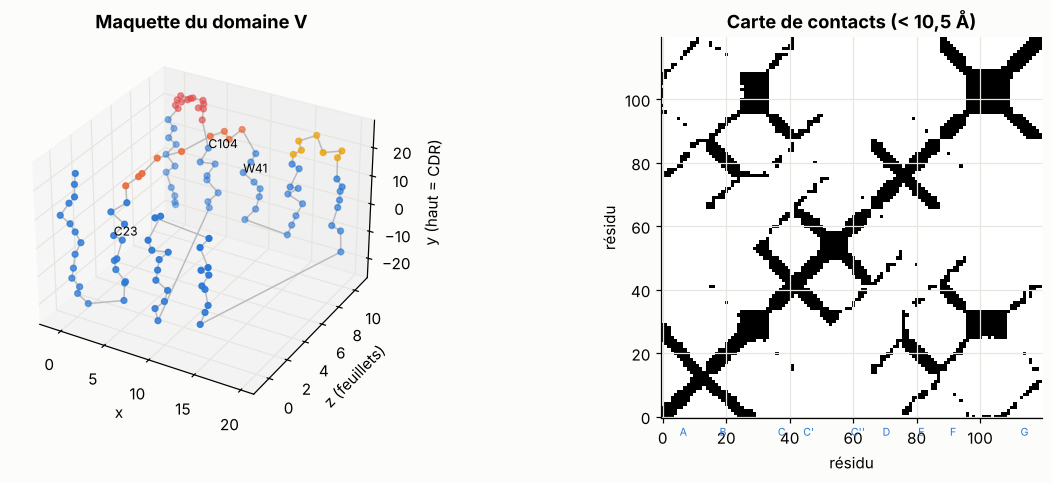

In [2]:
STRANDS = {  # name: (first, last, sheet, column, direction +1 = towards the CDR end)
    "A": (1, 15, 0, 0, -1), "B": (16, 26, 0, 1, +1), "C": (39, 46, 1, 2, -1), "C'": (47, 55, 1, 3, +1),
    "C''": (66, 74, 1, 4, -1), "D": (75, 84, 0, 3, +1), "E": (85, 96, 0, 2, -1), "F": (97, 104, 1, 1, +1),
    "G": (118, 128, 1, 0, -1),
}
SHEET_Z, STRAND_X, RISE = 10.0, 4.8, 3.3


def strand_of(base):
    for name, (a, b, *_rest) in STRANDS.items():
        if a <= base <= b:
            return name
    return "loop"


def template_coordinates():
    """Idealized C-alpha coordinates for IMGT positions 1..128 (insertions 111.x / 112.x handled later)."""
    xyz = {}
    for name, (a, b, sheet, col, direction) in STRANDS.items():
        n = b - a + 1
        for i, p in enumerate(range(a, b + 1)):
            y = (i - (n - 1) / 2) * RISE * direction
            xyz[p] = np.array([col * STRAND_X, y, sheet * SHEET_Z])
    loops = [(27, 38), (56, 65), (105, 117)]
    for a, b in loops:                                   # CDR loops: arcs above the top of the sandwich
        start, end = xyz[a - 1], xyz[b + 1]
        n = b - a + 1
        for i, p in enumerate(range(a, b + 1)):
            t = (i + 1) / (n + 1)
            point = (1 - t) * start + t * end
            point[1] = max(start[1], end[1]) + 2.5 + 7.0 * np.sin(np.pi * t)
            xyz[p] = point
    return xyz

TEMPLATE = template_coordinates()


def domain_coordinates(imgt_positions, noise=0.4, seed=0):
    """Coordinates of the residues of one V domain, following its own IMGT numbering (insertions interpolated)."""
    r = np.random.default_rng(seed)
    out = []
    for p in imgt_positions:
        base, ins = parse_pos(p)
        c = TEMPLATE[base].copy()
        if ins:                                          # CDR3 insertions: push further up the loop
            c = c + np.array([0.0, 1.2 * ins, 0.0])
        out.append(c + r.normal(0, noise, 3))
    return np.array(out)

dom = next(d for e in examples for d in e["domains"] if d["type"] == "V" and d["locus"] == "IGH")
ex0 = next(e for e in examples if dom in e["domains"])
pos0 = ex0["imgt_pos"][dom["start"]:dom["end"]]
X0 = domain_coordinates(pos0)
strand_label = [strand_of(parse_pos(p)[0]) for p in pos0]
region0 = [region_of(p) for p in pos0]

fig = plt.figure(figsize=(12, 4.5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot(X0[:, 0], X0[:, 2], X0[:, 1], color="#bbb", lw=1)
colors = [PALETTE[1] if r == "CDR1" else PALETTE[3] if r == "CDR2" else PALETTE[7] if r == "CDR3" else PALETTE[0] for r in region0]
ax.scatter(X0[:, 0], X0[:, 2], X0[:, 1], c=colors, s=14)
for p, name in [("23", "C23"), ("104", "C104"), ("41", "W41")]:
    if p in pos0:
        i = pos0.index(p); ax.text(X0[i, 0], X0[i, 2], X0[i, 1], name, fontsize=8)
ax.set_xlabel("x"); ax.set_ylabel("z (feuillets)"); ax.set_zlabel("y (haut = CDR)"); ax.set_title("Maquette du domaine V")
ax2 = fig.add_subplot(1, 2, 2)
D0 = cdist(X0, X0)
im = ax2.imshow(D0 < 10.5, cmap="Greys", origin="lower")
for name, (a, b, *_r) in STRANDS.items():
    idx = [i for i, p in enumerate(pos0) if a <= parse_pos(p)[0] <= b]
    if idx:
        ax2.text(np.mean(idx), -6, name, ha="center", fontsize=7, color=PALETTE[0])
ax2.set_title("Carte de contacts (< 10,5 Å)"); ax2.set_xlabel("résidu"); ax2.set_ylabel("résidu")
plt.tight_layout(); plt.show()
i23, i104 = pos0.index("23"), pos0.index("104")
print(f"sequence separation C23-C104: {i104 - i23} residues; spatial distance in the mock-up: {D0[i23, i104]:.1f} Å")

La carte de contacts montre la signature d'un sandwich β : des **anti-diagonales** (brins antiparallèles voisins dans un feuillet) et des blocs entre brins de feuillets opposés. Le contact C23–C104, à environ 75 résidus d'écart dans la séquence, est l'un de ces contacts à longue portée. (Dans une vraie structure, les Cα des deux cystéines sont à environ 5,5–6,5 Å ; la maquette, plus grossière, les place face à face d'un feuillet à l'autre.)

## 3. Cartes de contacts : ce que la séquence ne montre pas

Les CDR sont-ils plus proches entre eux dans l'espace que dans la séquence ? On mesure, pour chaque résidu de CDR, la fraction de ses voisins **spatiaux** qui sont aussi dans un CDR, et la même fraction pour ses voisins **dans la séquence** (±4 résidus).

In [3]:
v_items = [(e, d) for e in examples for d in e["domains"] if d["type"] == "V"]
rng.shuffle(v_items)
rows = []
for k, (e, d) in enumerate(v_items[:200]):
    pos = e["imgt_pos"][d["start"]:d["end"]]
    reg = np.array([region_of(p) for p in pos])
    X = domain_coordinates(pos, seed=k)
    D = cdist(X, X)
    is_cdr = np.char.startswith(reg.astype(str), "CDR")
    n = len(pos)
    for i in np.flatnonzero(is_cdr):
        spatial = np.flatnonzero((D[i] < 10.5) & (np.abs(np.arange(n) - i) > 4))
        seqnb = [j for j in range(max(0, i - 4), min(n, i + 5)) if j != i]
        other_cdr_spatial = [j for j in spatial if is_cdr[j] and reg[j] != reg[i]]
        rows.append(dict(region=reg[i], n_spatial=len(spatial), frac_other_cdr=len(other_cdr_spatial) / max(1, len(spatial)),
                         frac_cdr_seq=is_cdr[seqnb].mean()))
cdr_nb = pd.DataFrame(rows)
print(cdr_nb.groupby("region")[["n_spatial", "frac_other_cdr", "frac_cdr_seq"]].mean().round(2).to_string())

        n_spatial  frac_other_cdr  frac_cdr_seq
region                                         
CDR1        18.88            0.70          0.69
CDR2         5.34            0.59          0.56
CDR3        15.25            0.49          0.80


Lecture : les voisins spatiaux non locaux d'un résidu de CDR appartiennent souvent à **un autre CDR** (dans la maquette comme dans les vrais domaines V), alors que ses voisins de séquence ne peuvent par définition voir qu'un seul CDR. Un modèle qui « voit » la structure peut donc raisonner sur le **site de liaison** comme un tout.

## 4. GNN : faire passer des messages entre voisins dans l'espace

Un **réseau de neurones sur graphe** met à jour la représentation de chaque nœud en agrégeant celles de ses voisins. La couche la plus simple, la convolution de graphe (GCN, Kipf & Welling, 2017) :

$$H^{(l+1)} = \sigma\big(\hat{A}\, H^{(l)} W^{(l)}\big), \qquad \hat{A} = \tilde{D}^{-1/2} (A + I)\, \tilde{D}^{-1/2},$$

où $A$ est la matrice d'adjacence du graphe de résidus. Tout le choix de modélisation est dans $A$ : le graphe de la **chaîne** (voisins dans la séquence) ou le graphe **spatial** (contacts).

Expérience contrôlée : prédire si un résidu est dans un CDR **à partir de sa seule identité d'acide aminé** (20 dimensions), en agrégeant l'information de ses voisins. Avec le graphe de la chaîne, le GCN voit une fenêtre de séquence ; avec le graphe spatial, il voit le voisinage 3D. Même modèle, mêmes paramètres, seul $A$ change.

In [4]:
AA = "ACDEFGHIKLMNPQRSTVWY"


def normalized_adjacency(A):
    A = A + np.eye(len(A))
    d = 1 / np.sqrt(A.sum(1))
    return A * d[:, None] * d[None, :]


def graph_of(e, d, kind, seed):
    pos = e["imgt_pos"][d["start"]:d["end"]]
    seq = e["seq"][d["start"]:d["end"]]
    n = len(pos)
    if kind == "chaîne":
        A = (np.abs(np.arange(n)[:, None] - np.arange(n)[None, :]) <= 2).astype(float) - np.eye(n)
    else:
        D = cdist(domain_coordinates(pos, seed=seed), domain_coordinates(pos, seed=seed))
        A = ((D < 10.5) & ~np.eye(n, dtype=bool)).astype(float)
    Xf = np.zeros((n, 20)); Xf[np.arange(n), [AA.index(c) for c in seq]] = 1
    y = np.array([region_of(p).startswith("CDR") for p in pos], dtype=int)
    return normalized_adjacency(A), Xf, y


def train_gcn(graphs, hidden=32, epochs=60, lr=0.01, seed=0):
    r = np.random.default_rng(seed)
    W1 = r.normal(0, np.sqrt(2 / 20), (20, hidden)); W2 = r.normal(0, np.sqrt(2 / hidden), (hidden, 2))
    params = [W1, W2]; M = [np.zeros_like(p) for p in params]; V = [np.zeros_like(p) for p in params]; t = 0
    for ep in range(epochs):
        for k in r.permutation(len(graphs)):
            Ah, X, y = graphs[k]
            AX = Ah @ X; pre1 = AX @ params[0]; H1 = np.maximum(pre1, 0)
            AH = Ah @ H1; logits = AH @ params[1]
            p = np.exp(logits - logits.max(1, keepdims=True)); p /= p.sum(1, keepdims=True)
            g = p.copy(); g[np.arange(len(y)), y] -= 1; g /= len(y)
            gW2 = AH.T @ g
            gH1 = (Ah.T @ (g @ params[1].T)) * (pre1 > 0)
            gW1 = AX.T @ gH1
            t += 1
            for i, gr in enumerate([gW1, gW2]):
                M[i] = 0.9 * M[i] + 0.1 * gr; V[i] = 0.999 * V[i] + 0.001 * gr ** 2
                params[i] = params[i] - lr * (M[i] / (1 - 0.9 ** t)) / (np.sqrt(V[i] / (1 - 0.999 ** t)) + 1e-8)
    return params


def gcn_predict(params, Ah, X):
    return (Ah @ np.maximum(Ah @ X @ params[0], 0) @ params[1]).argmax(1)

results = []
for kind in ["aucun (résidu seul)", "chaîne", "spatial"]:
    if kind == "aucun (résidu seul)":
        build = lambda e, d, s: (np.eye(d["end"] - d["start"]),) + graph_of(e, d, "chaîne", s)[1:]
    else:
        build = lambda e, d, s, kind=kind: graph_of(e, d, kind, s)
    train_g = [build(e, d, k) for k, (e, d) in enumerate(v_items[:300])]
    test_g = [build(e, d, 1000 + k) for k, (e, d) in enumerate(v_items[300:400])]
    params_g = train_gcn(train_g)
    correct = sum((gcn_predict(params_g, Ah, X) == y).sum() for Ah, X, y in test_g)
    total = sum(len(y) for _, _, y in test_g)
    cdr_rec = sum(((gcn_predict(params_g, Ah, X) == 1) & (y == 1)).sum() for Ah, X, y in test_g) / sum((y == 1).sum() for _, _, y in test_g)
    results.append(dict(graph=kind, accuracy=correct / total, CDR_recall=cdr_rec))
print(pd.DataFrame(results).round(3).to_string(index=False))

              graph  accuracy  CDR_recall
aucun (résidu seul)     0.792       0.141
             chaîne     0.934       0.881
            spatial     0.978       0.963


Ce que l'expérience isole : avec la seule identité du résidu, un classifieur distingue mal CDR et frameworks (les compositions se recouvrent) ; agréger les voisins aide déjà ; le graphe **spatial** aide davantage, parce que le voisinage 3D d'un résidu de CDR est enrichi en résidus d'autres CDR (section 3). Sur de vraies structures, c'est ce principe qu'exploitent les modèles à base de graphes pour les anticorps (par exemple pour prédire le paratope).

> En pratique, on n'écrit pas les GCN à la main : PyTorch Geometric (`GCNConv`, `GATConv`) ou des réseaux **équivariants** (qui respectent rotations et translations, comme ceux d'AlphaFold ou de ProteinMPNN) font le travail. L'idée reste celle de cette cellule : la structure entre dans le modèle **par le graphe**.

## 5. Délimiter des domaines à partir de la structure

La tâche T1 de ProtAnnotML (délimiter les domaines) a une version structurale très naturelle : un domaine est une région de la chaîne **dense en contacts internes** et pauvre en contacts avec le reste. Le **partitionnement spectral** du graphe de contacts le formalise : le second vecteur propre du laplacien (vecteur de Fiedler) sépare le graphe en deux parties faiblement connectées ; le changement de signe le long de la chaîne donne la frontière.

On construit une chaîne « V + linker + C » : la maquette du domaine V, un linker étiré, et un second sandwich β (domaine C) translaté sous le premier.

boundary inside [V end - 2, C start + 2]: 95% | median |error| vs V end: 6 residues


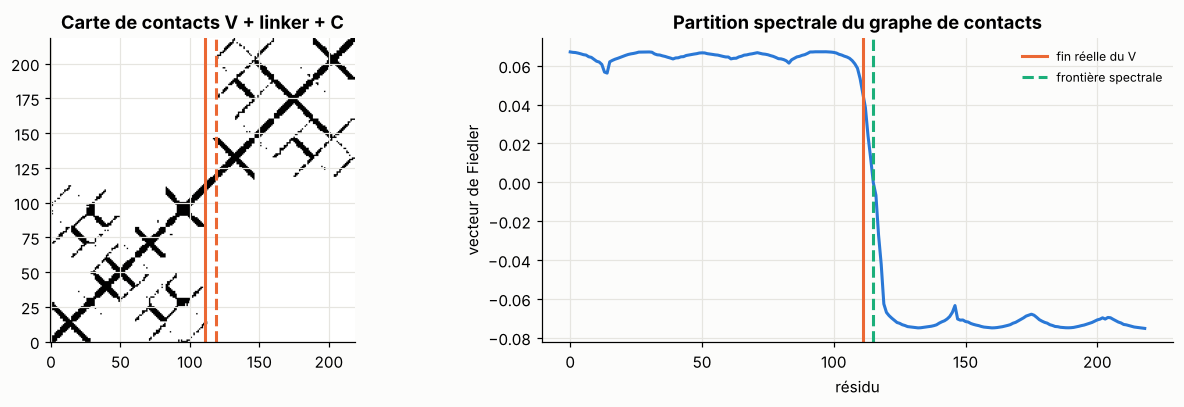

In [5]:
def c_domain_coordinates(n, offset, seed=0):
    """Idealized 7-strand C domain (sheets ABED / CFG), n residues spread over strands and short loops."""
    r = np.random.default_rng(seed)
    plan = [(0, 0, -1), (0, 1, +1), (1, 2, -1), (0, 3, +1), (0, 2, -1), (1, 1, +1), (1, 0, -1)]   # (sheet, column, direction)
    per = n // 7
    pts = []
    for s, (sheet, col, direction) in enumerate(plan):
        m = per if s < 6 else n - 6 * per
        for i in range(m):
            y = (i - (m - 1) / 2) * RISE * direction
            pts.append(np.array([col * STRAND_X, y, sheet * SHEET_Z]))
    return np.array(pts) + offset + r.normal(0, 0.4, (n, 3))


def chain_with_two_domains(e, d, n_linker, n_c, seed):
    pos = e["imgt_pos"][d["start"]:d["end"]]
    XV = domain_coordinates(pos, seed=seed)
    start, end = XV[-1], XV[-1] + np.array([0, -12.0 - 3.3 * n_linker / 2, 0])
    XL = np.array([start + (end - start) * (i + 1) / (n_linker + 1) for i in range(n_linker)]).reshape(-1, 3)
    XC = c_domain_coordinates(n_c, offset=end + np.array([0, -25.0, 0]), seed=seed)
    return np.vstack([XV, XL, XC]), len(pos)


def spectral_boundary(X, cutoff=10.5):
    A = (cdist(X, X) < cutoff).astype(float)
    np.fill_diagonal(A, 0)
    L = np.diag(A.sum(1)) - A
    vals, vecs = np.linalg.eigh(L)
    f = vecs[:, 1]
    signs = np.where(f > 0, 1, -1)
    n = len(X)
    # best single cut along the chain: minimise residues whose Fiedler sign disagrees with their side
    pos_before = np.concatenate([[0], np.cumsum(signs > 0)])
    neg_before = np.concatenate([[0], np.cumsum(signs < 0)])
    cuts = np.arange(1, n)
    cost_a = neg_before[cuts] + (pos_before[n] - pos_before[cuts])     # + before the cut, - after
    cost_b = pos_before[cuts] + (neg_before[n] - neg_before[cuts])     # - before the cut, + after
    best = int(cuts[np.argmin(np.minimum(cost_a, cost_b))])
    return best, f

errors = []
for k, (e, d) in enumerate(v_items[:150]):
    n_linker, n_c = int(rng.integers(0, 16)), int(rng.integers(90, 110))
    X, v_len = chain_with_two_domains(e, d, n_linker, n_c, seed=k)
    b, f = spectral_boundary(X)
    errors.append(dict(true_v_end=v_len, linker=n_linker, predicted=b, error=b - v_len,
                       within_linker=v_len - 2 <= b <= v_len + n_linker + 2))
err = pd.DataFrame(errors)
print(f"boundary inside [V end - 2, C start + 2]: {err.within_linker.mean():.0%} | median |error| vs V end: {err.error.abs().median():.0f} residues")

X, v_len = chain_with_two_domains(*v_items[0], n_linker=8, n_c=100, seed=0)
b, f = spectral_boundary(X)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].imshow(cdist(X, X) < 10.5, cmap="Greys", origin="lower")
axes[0].axvline(v_len, color=PALETTE[1]); axes[0].axvline(v_len + 8, color=PALETTE[1], ls="--")
axes[0].set_title("Carte de contacts V + linker + C")
axes[1].plot(f, color=PALETTE[0]); axes[1].axvline(v_len, color=PALETTE[1], label="fin réelle du V")
axes[1].axvline(b, color=PALETTE[2], ls="--", label="frontière spectrale")
axes[1].set_xlabel("résidu"); axes[1].set_ylabel("vecteur de Fiedler"); axes[1].legend(fontsize=8)
axes[1].set_title("Partition spectrale du graphe de contacts")
plt.tight_layout(); plt.show()

Le partitionnement spectral retrouve la frontière dans (ou à côté de) la région du linker, **sans aucune donnée d'entraînement** : il n'utilise que la géométrie. C'est l'idée de méthodes de délimitation de domaines à partir de structures (prédites ou expérimentales), et un **signal complémentaire** pour T1 : là où l'étiqueteur de séquence hésite (frontière V → C sans linker, notebook 3 du fil rouge), la structure prédite peut trancher. Limite : la frontière exacte au résidu près n'est pas définie par la géométrie seule ; la convention IMGT (fin du FR4 en 128) reste nécessaire.

## 6. Alphabets structuraux : la structure comme une séquence

Pour donner la structure à un modèle de **langage**, une idée puissante est de la **discrétiser** : chaque résidu reçoit une « lettre structurale » décrivant sa géométrie locale. **Foldseek** (van Kempen et al., 2024) a appris un alphabet de 20 états, « 3Di », qui décrit l'interaction de chaque résidu avec son plus proche voisin spatial ; la recherche de structures devient une recherche de séquences, des milliers de fois plus rapide. **SaProt** (Su et al., 2024) combine ensuite acide aminé et lettre 3Di en un seul jeton (vocabulaire 20 × 21) et entraîne un PLM dessus.

Version jouet : pour chaque résidu, on décrit sa géométrie par quelques distances (aux voisins de chaîne à ±2 et ±4, au plus proche voisin non local), puis on discrétise par k-moyennes en 8 états. On vérifie que ces états **capturent** la structure secondaire (brin ou boucle) sans qu'on la leur ait donnée.

In [6]:
from sklearn.cluster import KMeans


def local_descriptors(X):
    n = len(X)
    D = cdist(X, X)
    feats = []
    for i in range(n):
        f = [D[i, min(n - 1, max(0, i + o))] for o in (-4, -2, 2, 4)]
        far = D[i].copy(); far[max(0, i - 3):i + 4] = np.inf
        j = int(far.argmin())
        f += [far[j], D[max(0, j - 1), max(0, i - 1)], D[min(n - 1, j + 1), min(n - 1, i + 1)]]
        feats.append(f)
    return np.array(feats)

desc, ss = [], []
for k, (e, d) in enumerate(v_items[:200]):
    pos = e["imgt_pos"][d["start"]:d["end"]]
    desc.append(local_descriptors(domain_coordinates(pos, seed=k)))
    ss += ["boucle" if strand_of(parse_pos(p)[0]) == "loop" else "brin" for p in pos]
desc = np.vstack(desc); ss = np.array(ss)
km = KMeans(n_clusters=8, n_init=5, random_state=0).fit((desc - desc.mean(0)) / desc.std(0))
states = km.labels_
tab = pd.crosstab(states, ss, normalize="index").round(2)
tab["n"] = np.bincount(states)
print(tab.to_string())
p_ss = pd.Series(ss).value_counts(normalize=True)
h_ss = -(p_ss * np.log2(p_ss)).sum()
h_cond = sum(np.mean(states == s) * -sum(pv * np.log2(pv) for pv in pd.Series(ss[states == s]).value_counts(normalize=True)) for s in range(8))
print(f"mutual information between structural state and strand/loop: {h_ss - h_cond:.2f} bits (of {h_ss:.2f} possible)")

col_0  boucle  brin      n
row_0                     
0        0.12  0.88   1700
1        1.00  0.00   2098
2        0.39  0.61   2602
3        0.16  0.84   1794
4        0.15  0.85    705
5        0.38  0.62   3351
6        0.02  0.98  10409
7        0.14  0.86    882
mutual information between structural state and strand/loop: 0.35 bits (of 0.77 possible)


Les états découverts sans supervision séparent en partie brins et boucles : un état est purement « boucle », un autre presque purement « brin », et l'information mutuelle récupère un peu moins de la moitié de l'entropie de la structure secondaire (0,35 bit sur 0,77). Un vrai alphabet 3Di fait la même chose, en mieux, et en tenant compte de l'orientation (pas seulement des distances).

## 7. Sur de vraies structures : PDB, ESMFold, ImmuneBuilder, Foldseek, SaProt, ESM3

### 7.1 Lire une structure et la relier à la numérotation IMGT

In [ ]:
import gemmi                       # pip install gemmi  (or Bio.PDB)

st = gemmi.read_structure("7xyz.cif")
chain = st[0]["H"]
residues = [r for r in chain if r.find_atom("CA", "*")]
seq = gemmi.one_letter_code([r.name for r in residues])
ca = np.array([r.find_atom("CA", "*").pos.tolist() for r in residues])
# IMGT numbering of the chain with your own tool (ProtAnnotML or IMGT/DomainGapAlign), then:
# i23, i104 = imgt.index("23"), imgt.index("104"); print(np.linalg.norm(ca[i23] - ca[i104]))   # ~5.5-6.5 A for the disulfide

### 7.2 Prédire une structure

In [ ]:
import torch
from transformers import AutoTokenizer, EsmForProteinFolding

heavy_chain_sequence = "EVQLVESGAELVRPGESLKLSCKTSGFSLSNYGISWVRQPPGKGLEWLGWISPYNGDTNYAPKFKGRATLSVDKSKNTVYLQMNSLKAEDTAIYYCAR"  # replace
light_chain_sequence = "EIVLTQSPATMSVTPGERATLSCRSSESVTDLVAWYQQRPGQSPRLLIYDASNRATGIPARFSGSRSGTEYTLKISRVEAEDVGVYYCQQ"        # replace

# ESMFold: single sequence, no MSA; fast, good on frameworks, weaker on long CDR-H3
tok_f = AutoTokenizer.from_pretrained("facebook/esmfold_v1")
esmfold = EsmForProteinFolding.from_pretrained("facebook/esmfold_v1").eval().cuda()
with torch.no_grad():
    pdb_text = esmfold.infer_pdb(heavy_chain_sequence)
open("vh_esmfold.pdb", "w").write(pdb_text)

# ImmuneBuilder (ABodyBuilder2): antibody-specific, paired heavy + light chains
from ImmuneBuilder import ABodyBuilder2
model = ABodyBuilder2()
antibody = model.predict({"H": heavy_chain_sequence, "L": light_chain_sequence})
antibody.save("fv_abodybuilder2.pdb")

Pour les anticorps, les prédicteurs généralistes (AlphaFold 2/3, ESMFold) modélisent très bien les frameworks et les CDR canoniques ; le **CDR-H3** reste la partie la moins fiable (longueur et diversité). Les modèles spécialisés (ABodyBuilder2 / ImmuneBuilder, IgFold, qui utilise les plongements d'AntiBERTy) sont plus rapides et comparables ou meilleurs sur ce point. Garde toujours la confiance par résidu (pLDDT ou équivalent) et ne fais pas confiance à une boucle H3 prédite avec une faible confiance.

### 7.3 Foldseek : l'alphabet 3Di

In [ ]:
# shell (Foldseek installed): extract the 3Di string of each structure
#   foldseek createdb structures/ db
#   foldseek lndb db_h db_ss_h
#   foldseek convert2fasta db_ss db_3di.fasta
# then search structures like sequences:
#   foldseek easy-search query.pdb structures/ hits.m8 tmp --exhaustive-search 1

### 7.4 SaProt : un PLM sur des jetons « acide aminé + 3Di »

In [ ]:
from transformers import EsmTokenizer, EsmForMaskedLM

# SaProt tokens: amino acid (upper case) followed by its 3Di letter (lower case), '#' when the structure is unknown
aa, di = "EVQLVESGGG", "dpvvvvvddd"                 # toy example; real 3Di strings come from Foldseek
sa_seq = "".join(a + d for a, d in zip(aa, di))
tok_sa = EsmTokenizer.from_pretrained("westlake-repl/SaProt_650M_AF2")
saprot = EsmForMaskedLM.from_pretrained("westlake-repl/SaProt_650M_AF2")
enc = tok_sa(sa_seq, return_tensors="pt")
print(enc["input_ids"].shape)                          # one token per residue (+ <cls>, <eos>)

Pour ProtAnnotML, la variante intéressante est de remplacer le tronc ESM-2 par SaProt avec des structures **prédites** (ESMFold ou ImmuneBuilder) : le modèle reçoit alors explicitement la topologie du sandwich β. À tester par ablation (avec / sans 3Di, structures prédites / masquées `#`), et en mesurant le coût (une prédiction de structure par séquence).

### 7.5 ESM3 : séquence, structure et fonction dans un même modèle

ESM3 (Hayes et al., 2025) est un modèle génératif multimodal qui traite séquence, structure (jetons structuraux appris) et annotations de fonction comme des pistes masquables. Une petite version est diffusée en poids ouverts sous licence non commerciale (paquet `esm` d'EvolutionaryScale ; vérifie la licence et l'API, qui évoluent vite). Pour l'annotation, son intérêt principal est la représentation conjointe séquence-structure ; pour la conception d'anticorps, sa capacité de génération conditionnelle.

## 8. Ce que cela change pour ProtAnnotML

| Question | Apport de la structure | Coût / risque |
|---|---|---|
| T1 délimitation des domaines | contacts denses = domaine ; signal indépendant de la séquence | prédiction de structure par séquence (secondes sur GPU) |
| T2/T3 régions et numérotation | la numérotation IMGT **est** une coordonnée structurale ; utile pour les formats atypiques | faible gain attendu pour les domaines standard (déjà quasi parfaits par alignement) |
| T4 gène, espèce | peu d'apport direct | — |
| Interprétation | relier les caractéristiques (SAE) aux brins, à l'interface VH/VL, au paratope | demande des structures fiables |
| Au-delà de l'annotation | paratope, appariement VH/VL, développabilité | nouvelles données d'étiquetage |

Recommandation : garder ProtAnnotML **séquence d'abord** (rapide, sans dépendance lourde), et utiliser la structure prédite comme **source d'étiquettes ou de vérification** (par exemple pour valider les frontières de domaines de constructions inhabituelles), puis tester SaProt en ablation si le temps le permet.

## 9. Récapitulatif

| Notion | À retenir |
|---|---|
| Repliement Ig | sandwich β, feuillets ABED / GFCC'C", pont C23–C104 ; CDR = boucles BC, C'C", FG |
| Numérotation IMGT | une position = une place dans le repliement |
| Carte de contacts | anti-diagonales des brins antiparallèles, contacts à longue portée |
| GNN | $H' = \sigma(\hat{A} H W)$ ; tout est dans le choix du graphe |
| Domaines | partition spectrale du graphe de contacts |
| Alphabets structuraux | 3Di (Foldseek), jetons AA + 3Di (SaProt) |
| Prédicteurs | ESMFold, AlphaFold, ImmuneBuilder/ABodyBuilder2, IgFold ; CDR-H3 = point faible |

### 🏋️ Exercices

1. **Vraies structures.** Récupère 50 structures de Fv dans IMGT/3Dstructure-DB. Mesure la distance Cα–Cα C23–C104 et la proportion de voisins spatiaux de chaque CDR qui appartiennent à un autre CDR. Compare avec la maquette.
2. **Délimitation.** Sur des constructions réelles (scFv, Fab, bispécifiques), prédis la structure avec ESMFold et applique la partition spectrale (récursive pour plus de deux domaines). Compare les frontières avec celles d'IMGT/DomainGapAlign.
3. **GNN réel.** Avec PyTorch Geometric, entraîne un GCN sur des graphes de structures prédites pour prédire le paratope (résidus en contact avec l'antigène dans IMGT/3Dstructure-DB). Compare avec un modèle de séquence (PLM + tête linéaire).
4. **SaProt dans ProtAnnotML.** Remplace le tronc ESM-2 par SaProt (35M) avec des 3Di de structures prédites, et mesure l'effet sur T1 pour les constructions sans linker.

<details><summary>Indications</summary>

2. Pour plus de deux domaines, applique la coupe spectrale récursivement tant que la coupe est « nette » (faible nombre de contacts coupés rapporté à la taille des parties : coupe normalisée).
3. Attention à la fuite : découpe par cluster d'anticorps (les mêmes paratopes reviennent dans des structures redondantes de la PDB).
</details>